Script exists: True
CSV exists: True
CSV path: C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\fm_bands.csv

Return code: 0

Output:
loading
x: 576, y: 62, z: (-41.000000, -15.670000)
drawing
labeling
saving


Errors:


Image created: True


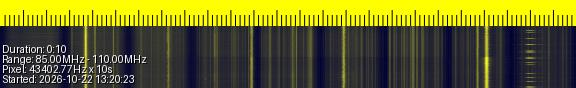

In [19]:
from pathlib import Path
import subprocess
import sys
from IPython.display import display, Image

script_path = Path.cwd() / "heatmap_routine.py"
csv_path = Path(FM_CSV)
image_path = Path.cwd() / "fm_band.jpg"

print("Script exists:", script_path.exists())
print("CSV exists:", csv_path.exists())
print("CSV path:", csv_path)

result = subprocess.run(
    [sys.executable, str(script_path), str(csv_path), str(image_path)],
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)
print("\nOutput:")
print(result.stdout)

print("\nErrors:")
print(result.stderr)

print("\nImage created:", image_path.exists())

image_path = Path.cwd() / "fm_band.jpg"

display(Image(filename=str(image_path)))

In [33]:
import numpy as np 
from pathlib import Path 
from load_file import load_file
from ffreq import ffreq

file_path = Path(r"C:\Users\arni-experiment\Documents\K.Boykin\SDR_PROJECT\rtl-sdr-64bit-20260906\absv1230_10sec.bin")

samples = load_file(file_path)

print("Number of complex samples:", len(samples))
print("Recording duration:", len(samples) / 2048000, "seconds")
print(samples.shape)


offsets = ffreq(
    samples, 
    fs=2_048_000,
    fr=1_000,
    dt=0.1,
    sq=0.1
)

print("Number of detected frequency bins:", len(offsets))
print("Detected frequency offsets (Hz):")
print(offsets)


Number of complex samples: 20480000
Recording duration: 10.0 seconds
(20480000,)
Number of detected frequency bins: 2039
Detected frequency offsets (Hz):
[-1023000. -1022000. -1021000. ...  1021000.  1022000.  1023000.]


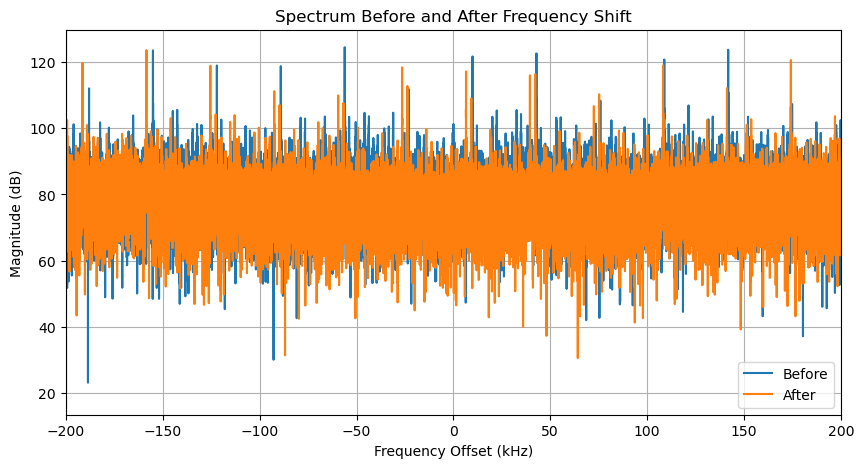

In [34]:
# The original RF waveform was sampled at 2.048 MHz ; we only need a few KHz to represent each channel 
# Demodulation corresponds to multiplying by a complex exponential 


fs = 2_048_000  # sampling freq 
dt = 1 / fs # sampling time 
t = np.arange(1, len(samples) + 1) * dt # time of each of the data samples 

# samples is the RF data loaded above and dm is the demodulated data 
dm = samples * np.exp(
    -1j * 2 * np.pi * (-1022000) * t
)

#--------------------------------------------------

N = 2**18  # 262,144 samples for FFT

# BEFORE SHIFT
X = np.fft.fftshift(np.fft.fft(samples[:N]))

# AFTER SHIFT
DM = np.fft.fftshift(np.fft.fft(dm[:N]))

freq = np.fft.fftshift(
    np.fft.fftfreq(N, d=1/fs)
)

plt.figure(figsize=(10, 5))

plt.plot(
    freq / 1000,
    20 * np.log10(np.abs(X) + 1e-12),
    label="Before"
)

plt.plot(
    freq / 1000,
    20 * np.log10(np.abs(DM) + 1e-12),
    label="After"
)

plt.xlim(-200, 200)
plt.xlabel("Frequency Offset (kHz)")
plt.ylabel("Magnitude (dB)")
plt.title("Spectrum Before and After Frequency Shift")
plt.legend()
plt.grid()

plt.show()

Original: 20480000
After first decimation: 2560000
After second decimation: 320000


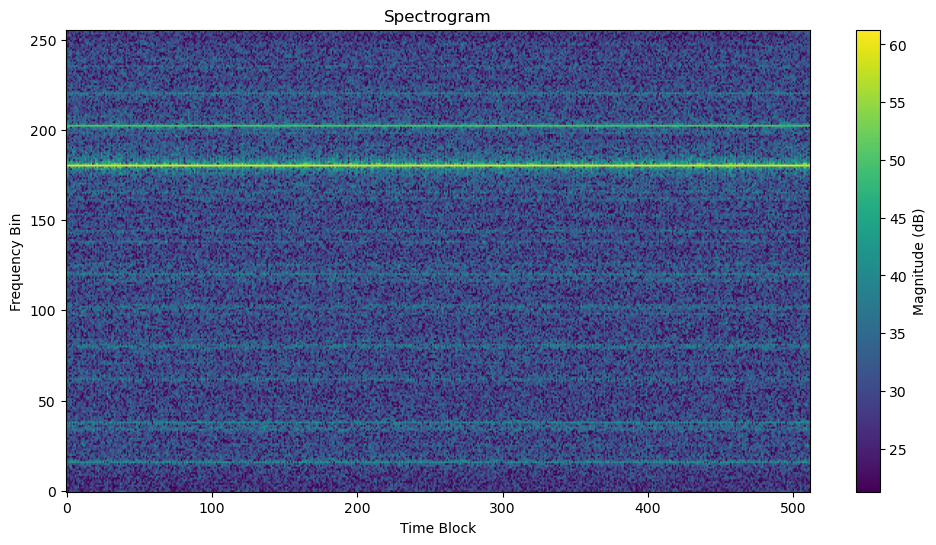

Audio sample rate: 32000.0
Audio samples: 320000
Audio sample rate: 32000.0
Audio duration: 10.0 seconds


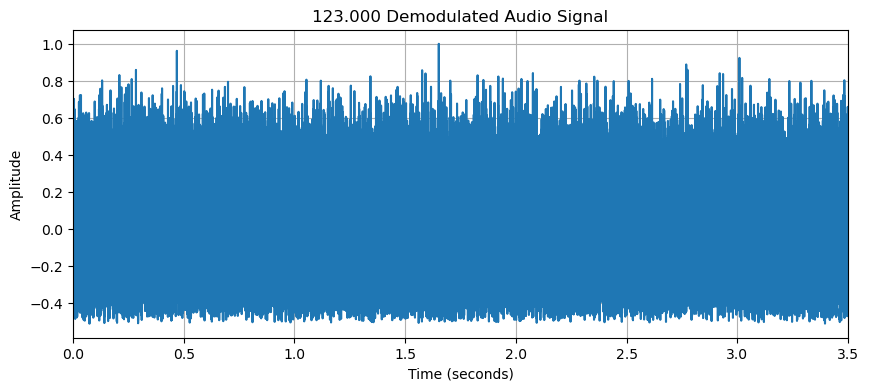

In [36]:
from scipy.signal import decimate 
from msg import msg 
from IPython.display import Audio 

# First decimation by 8 
dmd = decimate(dm, 8, ftype="fir")  # Orginal num of samples per sec divided by 8 ; stops here for FM signal 

# Second decimation by 8 
dmdd = decimate(dmd, 8, ftype="fir") # First decimation num of samples divided by 8 only if AM signals 


print("Original:", len(dm))
print("After first decimation:", len(dmd))
print("After second decimation:", len(dmdd)) 


ds = msg(dmdd, 1, 256, 512)

# AM demodulation 
am_demod = np.abs(dmdd)

# Once demodulated - can reduce for audio 
audio = am_demod - np.mean(am_demod)

fs_audio = fs / 64

print("Audio sample rate:", fs_audio)

audio = audio / np.max(np.abs(audio))

print("Audio samples:", len(audio))
print("Audio sample rate:", fs_audio)
print("Audio duration:", len(audio) / fs_audio, "seconds")

#Plays audio 
display(Audio(audio, rate=int(fs_audio)))


#Display final plot 
t_audio = np.arange(len(audio)) / fs_audio

plt.figure(figsize=(10, 4))
plt.plot(t_audio, audio)

plt.xlim(0, 3.5) # since recording is 10 secs long - best to zoom in on the first few seconds 
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("123.000 Demodulated Audio Signal")
plt.grid()

plt.show()